# AP 155 Lab Exercise
---
## Exercise 12: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Agbay, Tristan Michael
- _Student No._: 2024-00281
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
this helped me understand "https://labs.acme.byu.edu/Volume3/Metropolis/Metropolis.html" :>>

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import os
from matplotlib.patches import Patch

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

# 1. Setting Up the Ising Model

Initial lattice: m = -0.015 (expected 0 +/- 1/N = 0.050), H = 0
All spins up:    H = -800   (-2JN^2 = -800)
All spins down:  H = -800


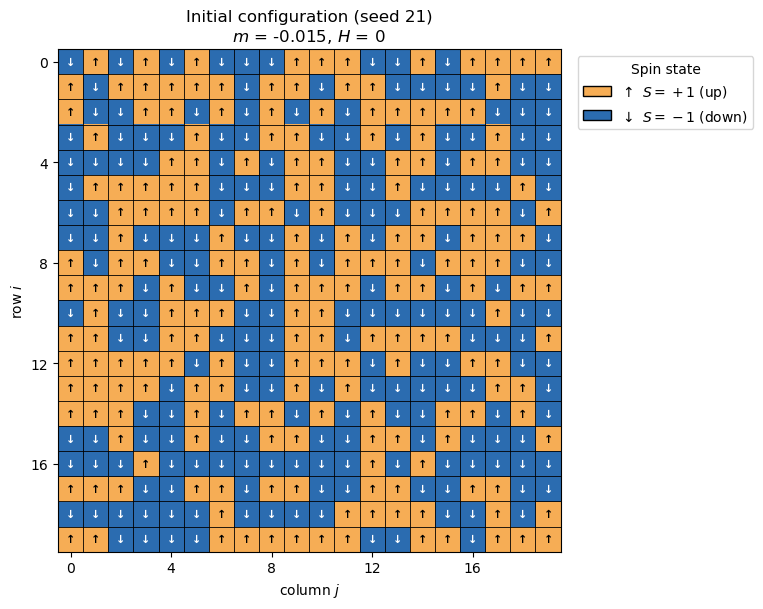

In [2]:
# Parameters (J = kB = 1)
N = 20                          # lattice size 
n_sites = N * N                 # one sweep = N^2 attempted flips
J = 1.0                         # interaction strength
kB = 1.0                        # Boltzmann constant
T_low = 1.0                     # temperature below T_C
T_high = 3.0                    # temperature above T_C 
T_C = 2 / math.log(1 + math.sqrt(2))   # Onsager's exact value, ~2.269
B_ext = 0.5                     # external field 
sweeps_long = 10_000            # Section 2
sweeps_run = 2_500              # Sections 3-5: 2,500 x 400 = 10^6 attempted flips
lattice_seeds = [21, 22, 23, 24]   # seeds of the different initial lattices
os.makedirs("figures", exist_ok=True)


def random_lattice(N, seed):
    # N x N lattice of +1/-1 spins with equal probability
    rng = np.random.default_rng(seed)
    return rng.choice(np.array([-1, 1]), size=(N, N))


def total_energy(S, J=1.0, B=0.0):
    # np.roll wraps the edges (periodic boundaries); down + right neighbors count each bond once
    bonds = S * (np.roll(S, -1, axis=0) + np.roll(S, -1, axis=1))
    return -J * np.sum(bonds) - B * np.sum(S)


def magnetization(S):
    # magnetization per spin, m = M / N^2
    return np.sum(S) / S.size


def plot_spins(S, title, fname):
    # spin map: orange = +1 (up), blue = -1 (down), with grid lines and an arrow per site
    colors = ["#2b6cb0", "#f6ad55"]
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    ax.imshow(S, cmap=plt.matplotlib.colors.ListedColormap(colors), vmin=-1, vmax=1)

    # grid lines on the cell borders (minor ticks at half-integers)
    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=0.6)
    ax.tick_params(which="minor", length=0)

    # up/down arrow in every cell
    for (i, j), s in np.ndenumerate(S):
        ax.text(j, i, "\u2191" if s > 0 else "\u2193", ha="center", va="center",
                fontsize=8, fontweight="bold", color="black" if s > 0 else "white")

    ax.set_xticks(range(0, N, 4))
    ax.set_yticks(range(0, N, 4))
    ax.set_xlabel("column $j$")
    ax.set_ylabel("row $i$")
    ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=colors[1], edgecolor="black", label="\u2191  $S=+1$ (up)"),
                       Patch(facecolor=colors[0], edgecolor="black", label="\u2193  $S=-1$ (down)")],
              loc="upper left", bbox_to_anchor=(1.02, 1), title="Spin state")
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()


S0 = random_lattice(N, lattice_seeds[0])
print(f"Initial lattice: m = {magnetization(S0):+.3f} (expected 0 +/- 1/N = {1/N:.3f}), H = {total_energy(S0, J):.0f}")
print(f"All spins up:    H = {total_energy(np.ones((N, N)), J):.0f}   (-2JN^2 = {-2*J*n_sites:.0f})")
print(f"All spins down:  H = {total_energy(-np.ones((N, N)), J):.0f}")

plot_spins(S0, f"Initial configuration (seed {lattice_seeds[0]})\n"
               f"$m$ = {magnetization(S0):+.3f}, $H$ = {total_energy(S0, J):.0f}", "figures/fig1_initial.png")

# 2. Implementing the Metropolis Algorithm

The Section 1 lattice is run for 10,000 sweeps at $T=1$.

T = 1.0: final m = -1.000, final H = -800
         averages of last 5,000 sweeps: |m| = 0.9993, H = -798.9


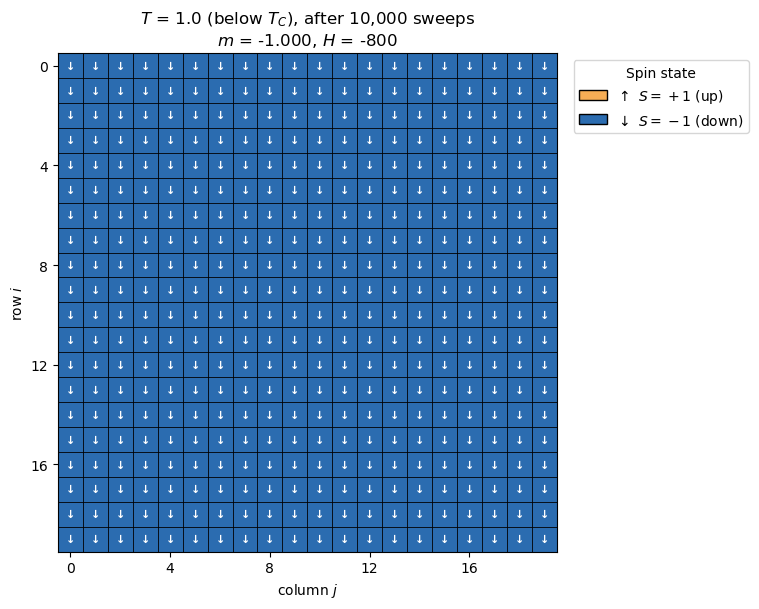

In [3]:
def metropolis(S, T, sweeps, seed, J=1.0, B=0.0, kB=1.0):
    # single-spin-flip Metropolis; returns final lattice, m and H after every sweep
    rng = np.random.default_rng(seed)
    N = S.shape[0]
    n = N * N
    spins = S.ravel().tolist()

    # neighbor table (up, down, left, right) of every flat site index, periodic wrap
    idx = np.arange(n).reshape(N, N)
    nbrs = np.stack([np.roll(idx, 1, 0), np.roll(idx, -1, 0),
                     np.roll(idx, 1, 1), np.roll(idx, -1, 1)], axis=-1).reshape(n, 4).tolist()

    # tables indexed [(s+1)//2][nn+4]; nn = neighbor sum in -4..4
    dH_tab = [[2 * s * (J * nn + B) for nn in range(-4, 5)] for s in (-1, 1)]
    P_tab = [[min(1.0, math.exp(-dH / (kB * T))) for dH in row] for row in dH_tab]

    H = total_energy(S, J, B)
    M = int(np.sum(S))
    ms, Hs = np.empty(sweeps + 1), np.empty(sweeps + 1)
    ms[0], Hs[0] = M / n, H

    for sweep in range(1, sweeps + 1):
        sites = rng.integers(0, n, n).tolist()     # random sites for one sweep
        us = rng.random(n).tolist()                # uniform numbers for acceptance
        for k, u in zip(sites, us):
            s = spins[k]
            a, b, c, d = nbrs[k]
            col = spins[a] + spins[b] + spins[c] + spins[d] + 4
            row = (s + 1) // 2
            if u < P_tab[row][col]:                # accept with min(1, e^(-dH/kT))
                spins[k] = -s
                H += dH_tab[row][col]
                M -= 2 * s
        ms[sweep], Hs[sweep] = M / n, H

    S_final = np.array(spins).reshape(N, N)
    assert math.isclose(H, total_energy(S_final, J, B)), "running energy does not match H"
    return S_final, ms, Hs


#10,000 sweeps (4 x 10^6 attempted flips) at T = 1
S_low, ms, Hs = metropolis(S0, T_low, sweeps_long, seed=100, J=J, B=0.0, kB=kB)
print(f"T = {T_low}: final m = {ms[-1]:+.3f}, final H = {Hs[-1]:.0f}")
print(f"         averages of last 5,000 sweeps: |m| = {np.abs(ms[-5000:]).mean():.4f}, H = {Hs[-5000:].mean():.1f}")

plot_spins(S_low, f"$T$ = {T_low} (below $T_C$), after {sweeps_long:,} sweeps\n"
                  f"$m$ = {ms[-1]:+.3f}, $H$ = {Hs[-1]:.0f}", "figures/fig2_final_low.png")

# 3. Investigating Spontaneous Magnetization
`run_set` runs the four initial lattices (seeds 11 to 14) for 2,500 sweeps each ($10^6$ attempted flips, the upper end of the suggested range) and records $m$ and $H$ after every sweep. Each run uses a flip seed different from its lattice seed. `plot_mE` plots $m$ (left) and $H$ (right) against sweeps. Equilibrium averages use the last 1,000 sweeps.

T = 1.0, B = 0.0, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = -0.9992, <H> = -798.8
T = 1.0, B = 0.0, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = -0.9993, <H> = -798.9
T = 1.0, B = 0.0, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.9994, <H> = -799.0
T = 1.0, B = 0.0, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = +0.9994, <H> = -799.0


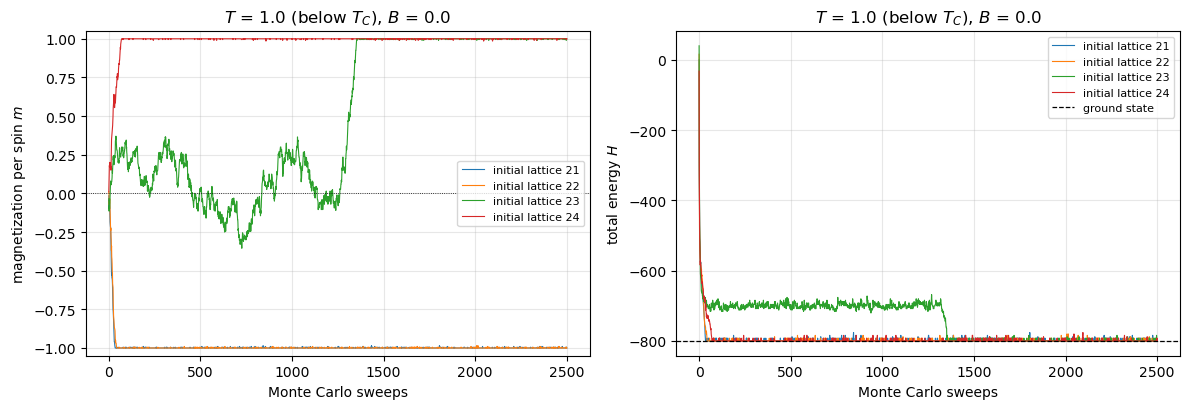

In [4]:
n_avg = 1_000     # sweeps used for the equilibrium averages


def run_set(T, B):
    # runs every initial lattice in lattice_seeds at temperature T and field B
    runs = []
    for s in lattice_seeds:
        _, ms, Hs = metropolis(random_lattice(N, s), T, sweeps_run, seed=s + 1000, J=J, B=B, kB=kB)
        runs.append((ms, Hs))
        print(f"T = {T}, B = {B}, lattice {s}: start m = {ms[0]:+.3f} | last {n_avg} sweeps: "
              f"<m> = {ms[-n_avg:].mean():+.4f}, <H> = {Hs[-n_avg:].mean():.1f}")
    return runs


def plot_mE(runs, T, B, fname):
    # m (left) and H (right) versus sweeps for every initial lattice
    side = "below" if T < T_C else "above"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    for s, (ms, Hs) in zip(lattice_seeds, runs):
        ax1.plot(ms, lw=0.8, label=f"initial lattice {s}")
        ax2.plot(Hs, lw=0.8, label=f"initial lattice {s}")
    ax1.axhline(0, color="k", lw=0.6, ls=":")
    ax2.axhline(-2 * J * n_sites - B * n_sites, color="k", lw=0.9, ls="--", label="ground state")
    ax1.set_ylim(-1.05, 1.05)
    ax1.set_ylabel("magnetization per spin $m$")
    ax2.set_ylabel("total energy $H$")
    for ax in (ax1, ax2):
        ax.set_xlabel("Monte Carlo sweeps")
        ax.set_title(f"$T$ = {T} ({side} $T_C$), $B$ = {B}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="best")
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()


# four different initial lattices at T = 1, no field
runs_low = run_set(T_low, 0.0)
plot_mE(runs_low, T_low, 0.0, "figures/fig3_mE_low.png")

# 4. Introducing an External Magnetic Field
The same four lattices are run with $B=0.5$. The field already enters `total_energy` through $-B\sum S_{i,j}$ and `metropolis` through the $\Delta H$ table, so only `B` changes. The ground-state line becomes $-2JN^2-BN^2=-1000$.

T = 1.0, B = 0.5, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = +0.9997, <H> = -999.5
T = 1.0, B = 0.5, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = +0.9997, <H> = -999.5
T = 1.0, B = 0.5, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.9998, <H> = -999.7
T = 1.0, B = 0.5, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = +0.9998, <H> = -999.6


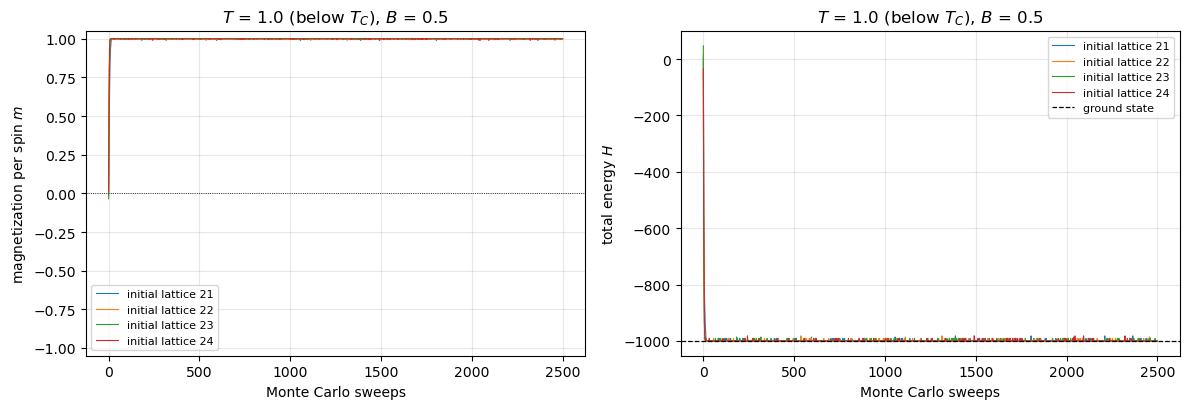

In [5]:
# same four initial lattices at T = 1, with B = 0.5
runs_B_low = run_set(T_low, B_ext)
plot_mE(runs_B_low, T_low, B_ext, "figures/fig4_mE_B_low.png")

# 5. Critical Temperature
Sections 2, 3, and 4 are repeated at $T=3.0$, above $T_C\approx2.269$, with the same lattices and flip seeds. A final table compares the equilibrium averages at both temperatures.

T = 3.0: final m = +0.045, final H = -312
         averages of last 5,000 sweeps: |m| = 0.1444, H = -327.5


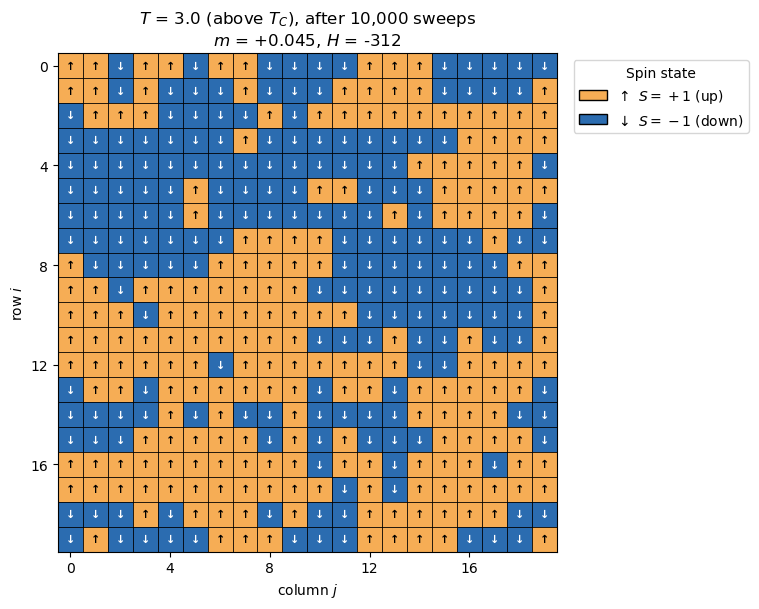

In [6]:
# Section 2 at T = 3.0: same initial lattice, 10,000 sweeps
S_high, ms, Hs = metropolis(S0, T_high, sweeps_long, seed=100, J=J, B=0.0, kB=kB)
print(f"T = {T_high}: final m = {ms[-1]:+.3f}, final H = {Hs[-1]:.0f}")
print(f"         averages of last 5,000 sweeps: |m| = {np.abs(ms[-5000:]).mean():.4f}, H = {Hs[-5000:].mean():.1f}")
plot_spins(S_high, f"$T$ = {T_high} (above $T_C$), after {sweeps_long:,} sweeps\n"
                   f"$m$ = {ms[-1]:+.3f}, $H$ = {Hs[-1]:.0f}", "figures/fig2_final_high.png")

T = 3.0, B = 0.0, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = -0.0393, <H> = -330.0
T = 3.0, B = 0.0, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = +0.0496, <H> = -329.6
T = 3.0, B = 0.0, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.0171, <H> = -326.8
T = 3.0, B = 0.0, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = -0.0165, <H> = -325.5


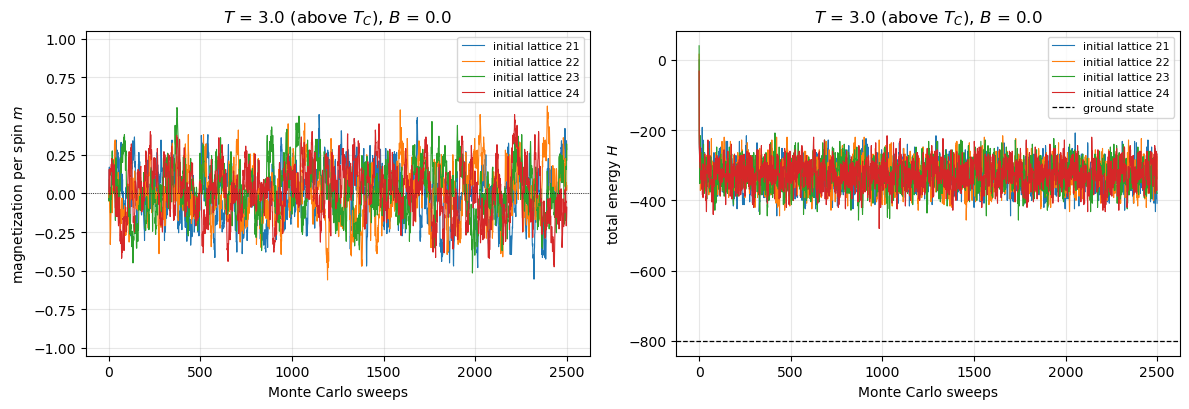

In [7]:
# Section 3 at T = 3.0: no field
runs_high = run_set(T_high, 0.0)
plot_mE(runs_high, T_high, 0.0, "figures/fig3_mE_high.png")

T = 3.0, B = 0.5, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = +0.7713, <H> = -699.2
T = 3.0, B = 0.5, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = +0.7636, <H> = -691.4
T = 3.0, B = 0.5, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.7688, <H> = -698.1
T = 3.0, B = 0.5, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = +0.7715, <H> = -699.6


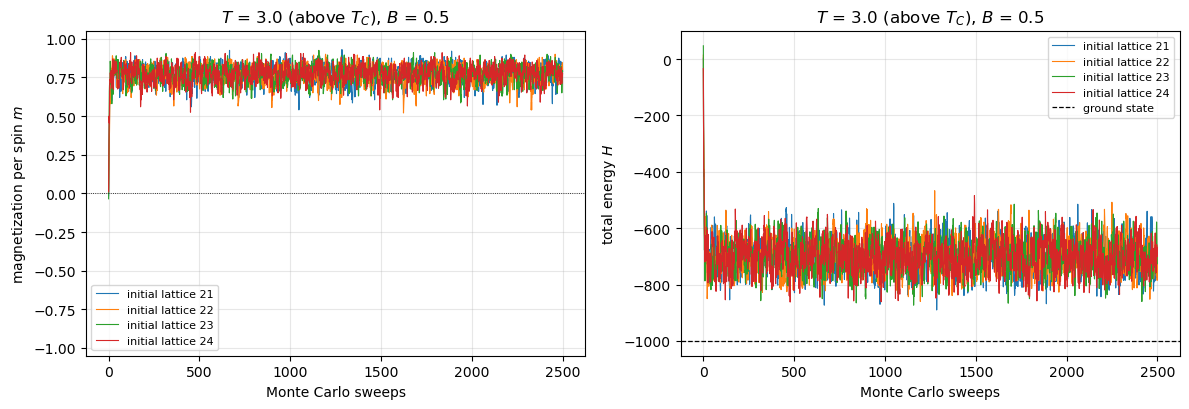

In [8]:
# Section 4 at T = 3.0: with B = 0.5
runs_B_high = run_set(T_high, B_ext)
plot_mE(runs_B_high, T_high, B_ext, "figures/fig4_mE_B_high.png")

In [9]:
# equilibrium averages pooled over the four lattices (last n_avg sweeps of each)
print(f"T_C = {T_C:.3f}")
print(f"{'T':>5} {'B':>5} {'<|m|>':>8} {'<m>':>8} {'<H>':>8} {'<H>/N^2':>8}")
for T, B, runs in ((T_low, 0.0, runs_low), (T_high, 0.0, runs_high),
                   (T_low, B_ext, runs_B_low), (T_high, B_ext, runs_B_high)):
    m_eq = np.concatenate([ms[-n_avg:] for ms, _ in runs])
    H_eq = np.concatenate([Hs[-n_avg:] for _, Hs in runs])
    print(f"{T:5.1f} {B:5.1f} {np.abs(m_eq).mean():8.4f} {m_eq.mean():+8.4f} {H_eq.mean():8.1f} {H_eq.mean()/n_sites:8.3f}")

T_C = 2.269
    T     B    <|m|>      <m>      <H>  <H>/N^2
  1.0   0.0   0.9993  +0.0001   -798.9   -1.997
  3.0   0.0   0.1404  +0.0027   -327.9   -0.820
  1.0   0.5   0.9998  +0.9998   -999.6   -2.499
  3.0   0.5   0.7688  +0.7688   -697.1   -1.743
